# Transfer-factor decomposition — do student-base animal priors explain cross-init transfer?

**The focus-20 campaign.** 20 fixed teacher recipes (one list, shared across animals *by design*)
are each cross-distilled into 6 PolyPythias student bases at 20 shared student-HP cells, for
**dog / cat / lion / pig**. Some (animal × student-base) cells transfer the trait well; others do
not. This notebook decomposes that pattern into interpretable factor groups and asks whether the
measured student-base *prior* — how much a base already likes an animal — explains it.

**The five factors:**

1. **Teacher imprint** — how strongly the teacher recipe carries the trait. A property of the
   *animal* (teacher list is identical across animals) ⇒ absorbed by an **animal fixed effect**
   (which also absorbs the *teacher-base* prior, since all teachers share pythia-160m).
2. **Teacher-base prior** — animal-level, folded into the animal FE (factor 1).
3. **Student-base prior `P_s(a)`** — a *measured* animal×base covariate; NOT absorbed by either FE
   and identified by the **within-animal cross-base contrast** (does base *s* over-perform its own
   average exactly on the animals it already favors?). Its coefficient `β` is the estimand of
   interest.
4. **ds-vs-ws structure** — do data-seed and weight-seed bases differ as *groups* after adjustment?
5. **Individual base quirks** — per-base fixed effects with/without the prior term.

> **Reading guide.** Transfer is a *hurdle*: a seed either collapses (loses the trait) or survives
> with a graded score. We split **survival** from **conditional transfer** (mean score | survived)
> and analyse each. Primary inference on the prior is a **within-animal permutation test** — the
> parametric cluster-robust p is optimistic given only ~15 animal×base clusters. Every table/figure
> below states its **row unit, aggregation, filter, and n**. Coverage is partial (some arms are
> still draining); sections print "arm not landed yet" rather than raising, and a plain re-run
> absorbs new data.

## 0. Setup

In [1]:
from __future__ import annotations

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import transfer_factors as tf
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")  # statsmodels small-cluster / separation chatter
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

DEAD = tf.DEAD  # 0.005; re-checked per animal in §2
ANIMAL_COLORS = {"dog": "#4c78a8", "cat": "#f58518", "lion": "#54a24b", "pig": "#e45756"}

cells_df, PARAM_TAGS, META = tf.load_focus20_design(ROOT)
CELL_TAGS = list(cells_df["student_tag"])
print(f"focus-20 design: {len(cells_df)} student cells, {len(PARAM_TAGS)} shared teachers, "
      f"epochs={META['epochs']}, student_seed={META['student_seed']}")

runs = tf.load_focus_runs(OUTPUT_ROOT, PARAM_TAGS, cells_df)
cells = tf.hurdle_cells(runs, dead=DEAD)
priors = tf.load_priors(OUTPUT_ROOT)
print(f"landed: {len(runs)} seed-runs -> {len(cells)} (animal×base×teacher×cell) rows; "
      f"{int(cells['cond'].notna().sum())} have >=1 surviving seed")

focus-20 design: 20 student cells, 20 shared teachers, epochs=20, student_seed=1


landed: 2866 seed-runs -> 2710 (animal×base×teacher×cell) rows; 2041 have >=1 surviving seed


## 1. Coverage — what has landed

**Row unit:** one (animal × base). **Columns:** distinct teachers landed (target 20), distinct
focus cells landed (target 20), and total seed-runs. **Filter:** focus-20 teachers × focus-20
cells only (older-campaign cells in the same dirs are dropped by the loader). Target per arm is
20 teachers × 20 cells × 1 seed = 400 seed-runs. Missing arms simply do not appear — no blank
rows; a re-run absorbs new data.

In [2]:
cov = (runs.groupby(["animal", "base_label"])
       .agg(teachers=("teacher_tag", "nunique"),
            cells=("student_tag", "nunique"),
            seed_runs=("test", "size"))
       .reset_index())
cov["group"] = cov["base_label"].map(tf._base_group)
cov = cov.sort_values(["animal", "base_label"]).reset_index(drop=True)
n_excluded = int((~runs.empty) and 0)  # focus filter applied inside loader; report raw vs kept below
display(cov)
print(f"arms landed: {len(cov)} of {len(tf.FOCUS_ANIMALS)}×{len(tf.FOCUS_BASE_LABELS)} = "
      f"{len(tf.FOCUS_ANIMALS)*len(tf.FOCUS_BASE_LABELS)} possible")
print("per animal, bases present:")
for a in tf.FOCUS_ANIMALS:
    present = sorted(cov[cov.animal == a].base_label)
    print(f"  {a:5s}: {present if present else 'NO DATA'}")

,animal,base_label,teachers,cells,seed_runs,group
0,cat,data-seed1,20,20,400,ds
1,cat,data-seed2,3,20,58,ds
2,cat,weight-seed1,20,20,400,ws
3,cat,weight-seed2,2,20,40,ws
4,dog,data-seed1,20,20,504,ds
5,dog,data-seed2,5,20,100,ds
6,dog,data-seed3,5,20,100,ds
7,dog,weight-seed1,20,20,444,ws
8,dog,weight-seed2,7,20,112,ws
9,dog,weight-seed3,2,20,26,ws


arms landed: 15 of 4×6 = 24 possible
per animal, bases present:
  dog  : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  cat  : ['data-seed1', 'data-seed2', 'weight-seed1', 'weight-seed2']
  lion : ['data-seed1', 'data-seed2', 'weight-seed1']
  pig  : ['data-seed1', 'weight-seed1']


How many non-focus cells were excluded? The loader keeps only the 20 focus cell tags; the
directories also hold larger legacy grids. We recompute the raw landed-cell count to report the
exclusion.

In [3]:
raw_counts = {}
for a in tf.FOCUS_ANIMALS:
    lineages = [(t, t, f"pythia-160m-{b}") for t in PARAM_TAGS for b in tf.FOCUS_BASE_LABELS]
    from subliminal_learning.analysis.collapse_law import load_law_runs
    _, r_all = load_law_runs(OUTPUT_ROOT, animal=a, lineages=lineages)
    if len(r_all):
        raw_counts[a] = (r_all["student_tag"].nunique(),
                         r_all[r_all.student_tag.isin(CELL_TAGS)]["student_tag"].nunique())
excl = pd.DataFrame(
    [{"animal": a, "raw_cells": rc, "focus_cells_kept": kc, "excluded": rc - kc}
     for a, (rc, kc) in raw_counts.items()])
display(excl)
print("Excluded cells are older-campaign HP grids sharing the same lineage dirs; only the 20 "
      "focus cells enter every analysis below.")

,animal,raw_cells,focus_cells_kept,excluded
0,dog,611,20,591
1,cat,117,20,97
2,lion,49,20,29
3,pig,49,20,29


Excluded cells are older-campaign HP grids sharing the same lineage dirs; only the 20 focus cells enter every analysis below.


## 2. DEAD threshold check — is 0.005 in the trough?

**Row unit:** one seed-run. **Aggregation:** histogram of `test` p(target) per animal on log-ish
bins. The DEAD line must sit in the empty trough between the dead mode and the live shoulder — the
threshold is **arm-checkable**, not inherited blind. Trough occupancy (fraction of seed-runs in the
bin straddling DEAD) is printed.

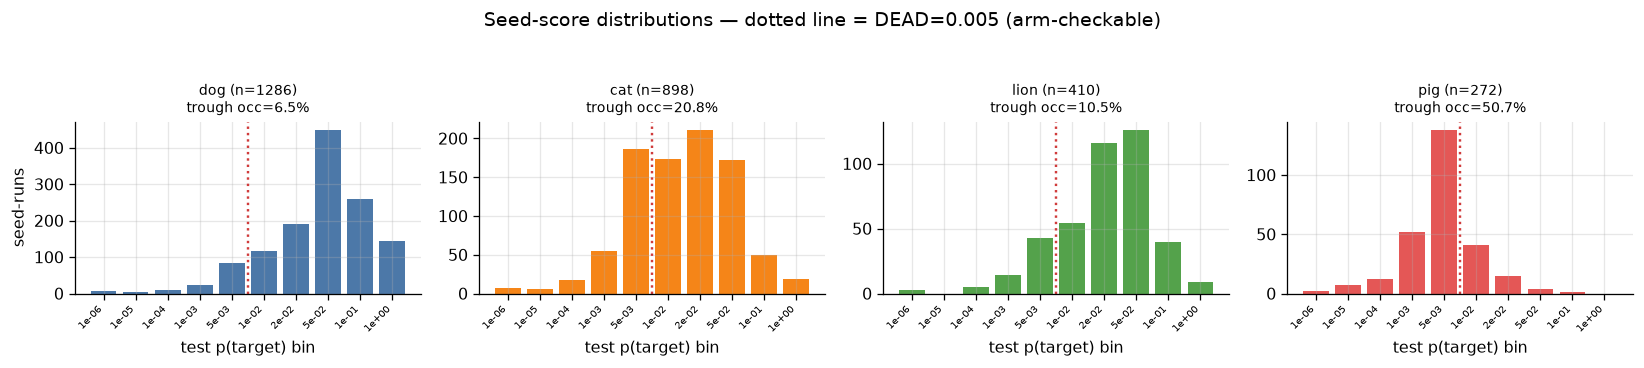

In [4]:
EDGES = [0, 1e-6, 1e-5, 1e-4, 1e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1, 1.0]
landed_animals = [a for a in tf.FOCUS_ANIMALS if (runs.animal == a).any()]
fig, axes = plt.subplots(1, len(landed_animals), figsize=(3.6 * len(landed_animals), 3.0),
                         squeeze=False)
for ax, a in zip(axes[0], landed_animals):
    sub = runs[runs.animal == a]
    hist = pd.cut(sub.test, EDGES, include_lowest=True).value_counts().sort_index()
    ax.bar(range(len(hist)), hist.values, color=ANIMAL_COLORS.get(a, "#888"))
    ax.set_xticks(range(len(hist)))
    ax.set_xticklabels([f"{e:.0e}" for e in EDGES[1:]], rotation=45, ha="right", fontsize=6)
    ax.axvline(hist.index.get_loc(pd.cut([DEAD], EDGES)[0]) + 0.5, color="#d03b3b", ls=":", lw=1.5)
    trough = pd.cut([DEAD], EDGES)[0]
    occ = hist[trough] / hist.sum()
    ax.set_title(f"{a} (n={len(sub)})\ntrough occ={occ:.1%}", fontsize=9)
    ax.set_xlabel("test p(target) bin")
axes[0][0].set_ylabel("seed-runs")
fig.suptitle(f"Seed-score distributions — dotted line = DEAD={DEAD} (arm-checkable)", y=1.05)
plt.tight_layout(); plt.show()

## 3. Priors — the two measured `P_s(a)`

Two measures of how much a base already likes an animal, both **per (animal × base)**:

- **logprob prior** — the base model's single-token log-probability of the animal word
  (`animal_selection/curated_scores.json`); higher = more favored.
- **behavioral prior** — the base model's own `base_p_target` on the actual eval prompts
  (favorite set); this is the exact quantity distillation must move.

These are the covariates entering §5. We show the (animal × 7-base) tables and their
cross-correlation.

In [5]:
foc = priors[priors.animal.isin(tf.FOCUS_ANIMALS)].copy()
logp_tab = foc.pivot(index="animal", columns="base_label", values="logprob_prior")
behav_tab = foc.pivot(index="animal", columns="base_label", values="behav_prior")
order = ["original"] + tf.FOCUS_BASE_LABELS
logp_tab = logp_tab.reindex(columns=[c for c in order if c in logp_tab.columns])
behav_tab = behav_tab.reindex(columns=[c for c in order if c in behav_tab.columns])
print("logprob prior — base single-token log p(animal); row=animal, col=base, higher=favored")
display(logp_tab.round(3))
print("behavioral prior — base_p_target on eval prompts; row=animal, col=base")
display(behav_tab.round(4))
m = foc.dropna(subset=["logprob_prior", "behav_prior"])
if len(m) > 2:
    from scipy.stats import pearsonr, spearmanr
    print(f"cross-measure correlation over {len(m)} (animal×base): "
          f"Pearson r={pearsonr(m.logprob_prior, m.behav_prior)[0]:.3f}, "
          f"Spearman ρ={spearmanr(m.logprob_prior, m.behav_prior)[0]:.3f}")

logprob prior — base single-token log p(animal); row=animal, col=base, higher=favored


base_label,original,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
animal,,,,,,,
cat,-4.396,-3.950,-4.216,-4.115,-4.115,-3.806,-4.787
dog,-3.533,-3.429,-3.496,-3.435,-4.934,-3.833,-4.244
lion,-4.001,-4.849,-4.540,-5.140,-4.347,-4.245,-5.257
pig,-3.729,-4.075,-4.622,-4.672,-5.266,-4.246,-4.543


behavioral prior — base_p_target on eval prompts; row=animal, col=base


base_label,original,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
animal,,,,,,,
cat,0.0036,0.0048,0.0058,0.0045,0.0053,0.0074,0.0037
dog,0.0096,0.0119,0.0111,0.0085,0.0061,0.0124,0.0064
lion,0.0062,0.0053,0.0046,0.0032,0.0044,0.0055,0.0039
pig,0.0036,0.0031,0.0021,0.0016,0.0017,0.0035,0.0023


cross-measure correlation over 28 (animal×base): Pearson r=0.695, Spearman ρ=0.650


## 4. Transfer table — survival and conditional transfer

**Row unit:** one (animal × base), aggregated over the landed teachers × cells. **Left:** survival
rate (fraction of seed-runs with test ≥ DEAD). **Right:** conditional transfer (mean test over
surviving seeds). Each cell is annotated with **n** = seed-runs behind it. Built only from landed
arms; empty arms are blank.

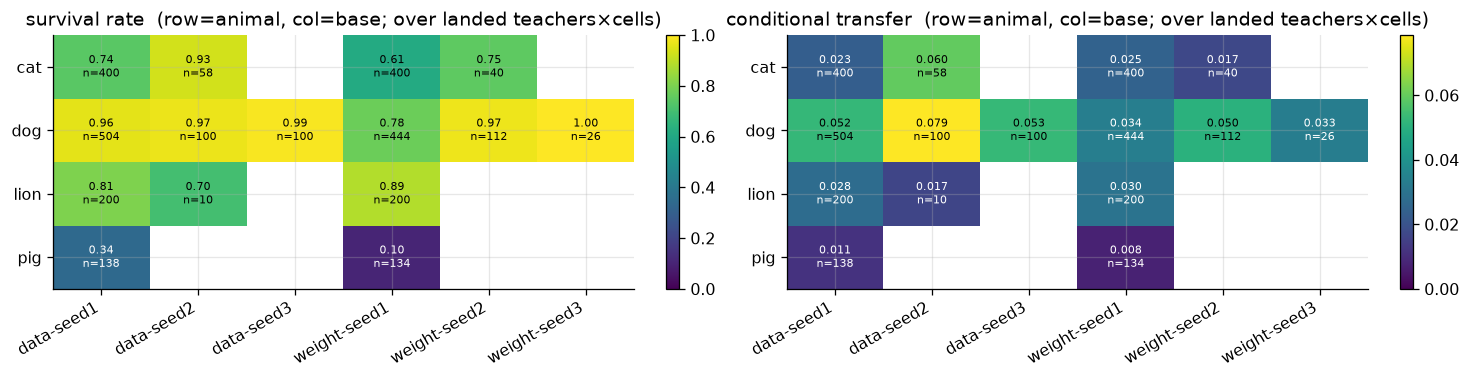

In [6]:
agg = (cells.groupby(["animal", "base_label"])
       .agg(n=("n_seeds", "sum"),
            surv=("n_alive", "sum"),
            surv_rate=("n_alive", lambda s: s.sum()),
            cond=("cond", "mean"))
       .reset_index())
# survival rate = total alive / total seeds
tot = cells.groupby(["animal", "base_label"]).agg(alive=("n_alive", "sum"),
                                                   seeds=("n_seeds", "sum")).reset_index()
agg = agg.merge(tot, on=["animal", "base_label"])
agg["surv_rate"] = agg["alive"] / agg["seeds"]

surv_p = agg.pivot(index="animal", columns="base_label", values="surv_rate")
cond_p = agg.pivot(index="animal", columns="base_label", values="cond")
n_p = agg.pivot(index="animal", columns="base_label", values="n")
cols = [c for c in tf.FOCUS_BASE_LABELS if c in surv_p.columns]
surv_p, cond_p, n_p = surv_p[cols], cond_p[cols], n_p[cols]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, tab, title, fmt in [(axes[0], surv_p, "survival rate", "{:.2f}"),
                            (axes[1], cond_p, "conditional transfer", "{:.3f}")]:
    im = ax.imshow(tab.values, aspect="auto", cmap="viridis", vmin=0,
                   vmax=1 if title.startswith("surv") else np.nanmax(cond_p.values))
    ax.set_xticks(range(len(tab.columns))); ax.set_xticklabels(tab.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(tab.index))); ax.set_yticklabels(tab.index)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, fmt.format(v) + f"\nn={int(n_p.values[i, j])}",
                        ha="center", va="center", fontsize=7,
                        color="white" if v < 0.6 * np.nanmax(tab.values) else "black")
    ax.set_title(f"{title}  (row=animal, col=base; over landed teachers×cells)")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 5. FE + prior decomposition — does the student-base prior explain transfer?

**Row unit:** one (animal × base × teacher × cell). Response = logit of conditional transfer
(survivors only) or empirical logit of survival. Regressors: `C(animal) + C(base) + prior_z`,
weighted by surviving-seed (or total-seed) counts, **cluster-robust on the animal×base pair**. The
animal FE absorbs teacher-side effects; the base FE absorbs student quirks; `β` on the z-scored
prior is the within-animal cross-base contrast.

The **permutation test** is the primary inference (parametric p is optimistic with ~15 clusters):
residualize by animal+base FEs, aggregate to (animal×base) means, and permute the prior **within
each animal** 2000× (fixed seed).

In [7]:
fit_rows = []
perm_res = {}
for prior_col in ["logprob_prior", "behav_prior"]:
    n_avail = priors.dropna(subset=[prior_col]).merge(
        cells[["animal", "base_label"]].drop_duplicates(), on=["animal", "base_label"]).shape[0]
    if n_avail == 0:
        print(f"{prior_col}: not available for any landed arm — skipping")
        continue
    for resp in ["cond", "surv"]:
        fit = tf.fe_prior_fit(cells, priors, prior_col, response=resp)
        perm = tf.prior_permutation_test(cells, priors, prior_col, response=resp,
                                         n_perm=2000, seed=0)
        perm_res[(prior_col, resp)] = (fit, perm)
        fit_rows.append({"prior": prior_col, "response": resp, "beta": fit.beta, "se": fit.se,
                         "p_cluster": fit.p, "n": fit.nobs, "n_clusters": fit.n_clusters,
                         "perm_slope": perm["obs_slope"], "p_perm": perm["p_two_sided"]})
fit_tab = pd.DataFrame(fit_rows)
print("WLS β (z-scored prior) with cluster-robust SE + within-animal permutation p.")
print("Row unit of the fit: (animal×base×teacher×cell). p_cluster is optimistic (few clusters); "
      "p_perm is primary.")
display(fit_tab.round(4))

WLS β (z-scored prior) with cluster-robust SE + within-animal permutation p.
Row unit of the fit: (animal×base×teacher×cell). p_cluster is optimistic (few clusters); p_perm is primary.


,prior,response,beta,se,p_cluster,n,n_clusters,perm_slope,p_perm
0,logprob_prior,cond,0.1594,0.0181,0.0000,2041,15,0.0718,0.2570
1,logprob_prior,surv,0.1537,0.0377,0.0000,2710,15,0.0592,0.1350
2,behav_prior,cond,0.2817,0.0256,0.0000,2041,15,0.0589,0.2245
3,behav_prior,surv,0.1843,0.0524,0.0004,2710,15,0.0143,0.4195


**The money plot.** One marker per (animal × base): FE-residualized conditional transfer vs
the prior, colored by animal, labeled by base. A positive trend = the prior explains within-animal
cross-base differences. Verdict printed from the permutation test.

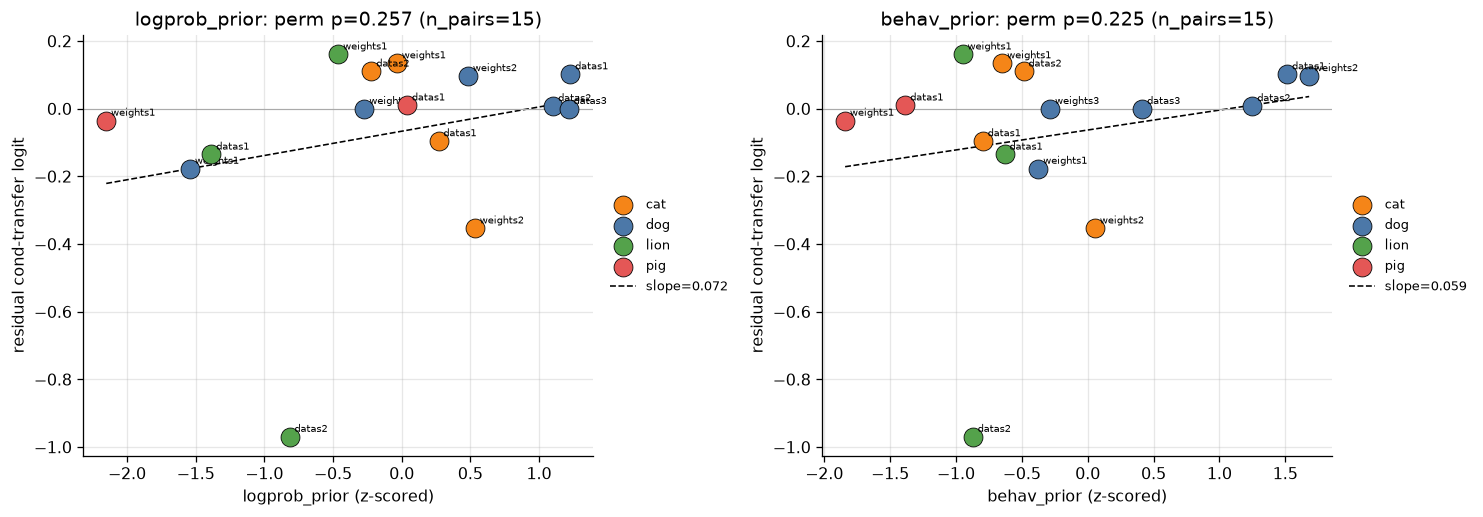

VERDICT [logprob_prior]: the student-base prior is NOT significant at the within-animal permutation test (slope=0.072, p=0.257); cluster-robust WLS β=0.159 (SE 0.018, p=1.11e-18, optimistic).
VERDICT [behav_prior]: the student-base prior is NOT significant at the within-animal permutation test (slope=0.059, p=0.225); cluster-robust WLS β=0.282 (SE 0.026, p=3.14e-28, optimistic).


In [8]:
import statsmodels.formula.api as smf

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, prior_col in zip(axes, ["logprob_prior", "behav_prior"]):
    key = (prior_col, "cond")
    if key not in perm_res:
        ax.text(0.5, 0.5, f"{prior_col}\narm not landed yet", ha="center", va="center")
        ax.axis("off"); continue
    df = tf._prep_fit_frame(cells, priors, prior_col, "cond")
    rm = smf.wls("y ~ C(animal) + C(base_label)", data=df, weights=df["w"]).fit()
    df = df.assign(_resid=rm.resid)
    agg = (df.groupby(["animal", "base_label"])
           .apply(lambda g: pd.Series({"resid": np.average(g["_resid"], weights=g["w"]),
                                        "prior_z": g["prior_z"].iloc[0]}), include_groups=False)
           .reset_index())
    for a in agg.animal.unique():
        s = agg[agg.animal == a]
        ax.scatter(s.prior_z, s.resid, s=140, color=ANIMAL_COLORS.get(a, "#888"),
                   label=a, edgecolor="k", linewidth=0.5, zorder=3)
        for _, r in s.iterrows():
            ax.annotate(r.base_label.replace("-seed", "s"), (r.prior_z, r.resid),
                        fontsize=6, xytext=(3, 3), textcoords="offset points")
    fit, perm = perm_res[key]
    xs = np.linspace(agg.prior_z.min(), agg.prior_z.max(), 20)
    ax.plot(xs, perm["obs_slope"] * (xs - agg.prior_z.mean()) + agg.resid.mean(),
            color="k", ls="--", lw=1, label=f"slope={perm['obs_slope']:.3f}")
    ax.axhline(0, color="#aaa", lw=0.7)
    ax.set_xlabel(f"{prior_col} (z-scored)"); ax.set_ylabel("residual cond-transfer logit")
    ax.set_title(f"{prior_col}: perm p={perm['p_two_sided']:.3f} (n_pairs={perm['n_pairs']})")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

for prior_col in ["logprob_prior", "behav_prior"]:
    key = (prior_col, "cond")
    if key not in perm_res:
        print(f"{prior_col}: not landed"); continue
    fit, perm = perm_res[key]
    sig = "SIGNIFICANT" if perm["p_two_sided"] < 0.05 else "NOT significant"
    print(f"VERDICT [{prior_col}]: the student-base prior is {sig} at the within-animal permutation "
          f"test (slope={perm['obs_slope']:.3f}, p={perm['p_two_sided']:.3f}); "
          f"cluster-robust WLS β={fit.beta:.3f} (SE {fit.se:.3f}, p={fit.p:.3g}, optimistic).")

## 6. Factor 1 — teacher imprint

**Row unit:** one teacher, within an animal. Per-teacher mean conditional transfer (averaged over
bases × cells) vs a teacher covariate: `teacher_p`, the teacher base's own trait score (favorite
`p_target` for pythia-160m). **Caveat:** `teacher_p` is seed-averaged over ft-seeds {0,1,2}, but
the campaign teachers are **tseed 1** specifically — so this is a proxy. Per-animal Pearson/Spearman
plus a pooled animal-FE fit.

Per-teacher cross-init transfer vs teacher_p (proxy; tseed-averaged). Row unit: teacher within animal; POOLED = animal-FE OLS partial.


,animal,r,rho,n,beta,p
0,cat,0.2656,0.1774,20,NaN,NaN
1,dog,0.0168,-0.0451,20,NaN,NaN
2,lion,0.0947,-0.0182,10,NaN,NaN
3,pig,0.3472,0.5357,7,NaN,NaN
4,POOLED,0.0671,NaN,57,3.3793,0.6296


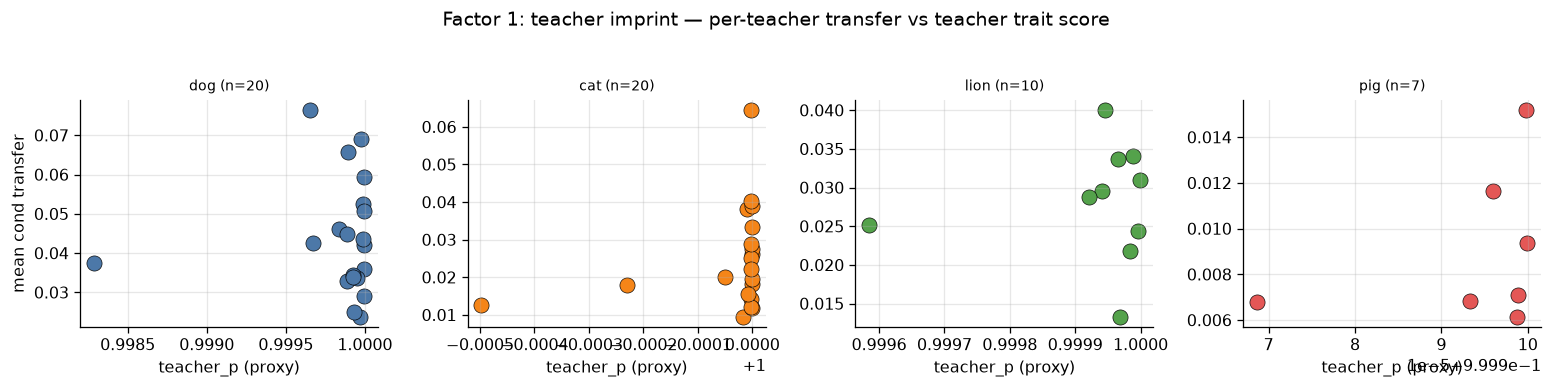

In [9]:
teacher_cov = tf.teacher_covariates(OUTPUT_ROOT, PARAM_TAGS)
f1 = tf.factor1_table(cells, teacher_cov)
print("Per-teacher cross-init transfer vs teacher_p (proxy; tseed-averaged). "
      "Row unit: teacher within animal; POOLED = animal-FE OLS partial.")
display(f1.round(4))

per_teacher = (cells[cells["cond"].notna()]
               .groupby(["animal", "teacher_tag"])["cond"].mean().reset_index()
               .merge(teacher_cov, on=["animal", "teacher_tag"], how="left"))
landed = [a for a in tf.FOCUS_ANIMALS if (per_teacher.animal == a).any()]
fig, axes = plt.subplots(1, len(landed), figsize=(3.4 * len(landed), 3.2), squeeze=False)
for ax, a in zip(axes[0], landed):
    s = per_teacher[per_teacher.animal == a]
    ax.scatter(s.teacher_p, s.cond, s=90, color=ANIMAL_COLORS.get(a, "#888"),
               edgecolor="k", linewidth=0.4)
    ax.set_title(f"{a} (n={len(s)})", fontsize=9)
    ax.set_xlabel("teacher_p (proxy)")
axes[0][0].set_ylabel("mean cond transfer")
fig.suptitle("Factor 1: teacher imprint — per-teacher transfer vs teacher trait score", y=1.04)
plt.tight_layout(); plt.show()

## 7. ds vs ws residual structure — factors 4 & 5

**Row unit:** one student base. Fitted base fixed effects (centered), from the conditional-transfer
logit regression, **with and without** the prior term. CIs are a teacher-clustered bootstrap
(1000 resamples, fixed seed). Group means for data-seed vs weight-seed bases. **Honest caveat:**
only 2–3 bases per group at current coverage — group means are suggestive, not conclusive.

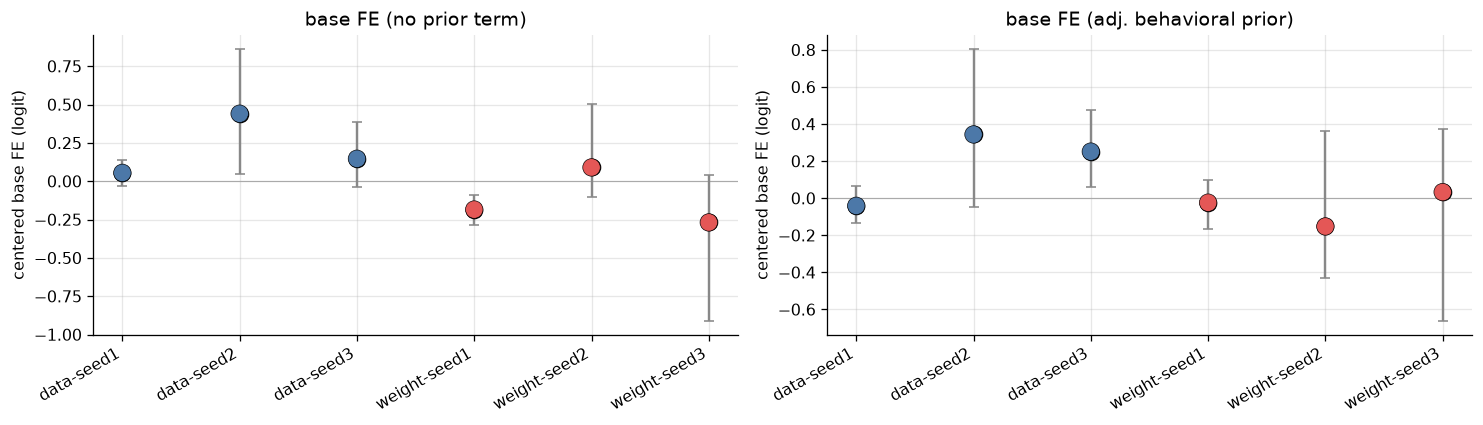

[no prior] ds mean FE=+0.214 (n=3 bases), ws mean FE=-0.121 (n=3 bases), ds-ws gap=+0.335
[prior-adjusted] ds mean FE=+0.185 (n=3 bases), ws mean FE=-0.048 (n=3 bases), ds-ws gap=+0.232


In [10]:
be_noprior = tf.base_effects(cells, n_boot=1000, seed=0)
be_prior = tf.base_effects(cells, priors=priors, prior_col="behav_prior", n_boot=1000, seed=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, be, title in [(axes[0], be_noprior, "base FE (no prior term)"),
                      (axes[1], be_prior, "base FE (adj. behavioral prior)")]:
    be = be.sort_values("base_label").reset_index(drop=True)
    colors = ["#4c78a8" if g == "ds" else "#e45756" for g in be.group]
    ax.errorbar(range(len(be)), be.fe, yerr=[be.fe - be.ci_lo, be.ci_hi - be.fe],
                fmt="o", ms=10, color="k", ecolor="#888", capsize=3, zorder=3)
    ax.scatter(range(len(be)), be.fe, s=120, c=colors, zorder=4, edgecolor="k", linewidth=0.4)
    ax.set_xticks(range(len(be))); ax.set_xticklabels(be.base_label, rotation=30, ha="right")
    ax.axhline(0, color="#aaa", lw=0.7); ax.set_ylabel("centered base FE (logit)")
    ax.set_title(title)
plt.tight_layout(); plt.show()

for name, be in [("no prior", be_noprior), ("prior-adjusted", be_prior)]:
    g = be.groupby("group").fe.agg(["mean", "count"])
    ds = g.loc["ds", "mean"] if "ds" in g.index else float("nan")
    ws = g.loc["ws", "mean"] if "ws" in g.index else float("nan")
    nds = int(g.loc["ds", "count"]) if "ds" in g.index else 0
    nws = int(g.loc["ws", "count"]) if "ws" in g.index else 0
    print(f"[{name}] ds mean FE={ds:+.3f} (n={nds} bases), ws mean FE={ws:+.3f} (n={nws} bases), "
          f"ds-ws gap={ds - ws:+.3f}")

## 8. Interpretation — what can and cannot be concluded now

- **Coverage is partial.** Several arms (weight-seed3, data-seed3 for most animals; lion/pig
  beyond ds1/ws1) are thin or absent, so the within-animal cross-base contrast rests on ~15
  (animal × base) points. The permutation test is the honest inference at this n.
- **The prior verdict** printed in §5 is the headline: whether the measured student-base prior
  (logprob and behavioral) explains within-animal cross-base transfer, net of animal and base
  fixed effects. Read the permutation p, not the cluster-robust p.
- **Factor 1** (teacher imprint) uses a tseed-averaged proxy for the tseed-1 campaign teachers;
  treat per-animal correlations as indicative.
- **ds-vs-ws** rests on 2–3 bases per group — a group-mean difference is suggestive only.
- This notebook is **re-run-to-update**: as arms drain, re-execute top-to-bottom and every table,
  figure, and verdict refreshes from disk with no code change.